# 12 · Interpreting models: permutation importance, partial dependence, SHAP

Three different questions:

| Question | Tool |
|---|---|
| Which features does the model *rely on* overall? | **Permutation importance** (on held-out data) |
| How does the prediction change as one feature varies? | **Partial dependence (PDP)** and **ICE** curves |
| Why did the model make *this* prediction? | **SHAP values** (additive per-feature contributions) |

All of these describe the **model**, not causality in the world. Correlated features share or swap credit.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

In [2]:
import lightgbm as lgb
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

X, y = fetch_california_housing(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
model = lgb.LGBMRegressor(n_estimators=800, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=SEED, verbose=-1).fit(X_train, y_train)
print(f"test RMSE: {np.sqrt(np.mean((y_test - model.predict(X_test)) ** 2)):.3f}")

test RMSE: 0.428


## 1. Permutation importance
Shuffle one column in the test set and measure how much the score drops. Model-agnostic and honest, but if two features are strongly correlated, shuffling one barely hurts (the other covers for it), so both look unimportant.

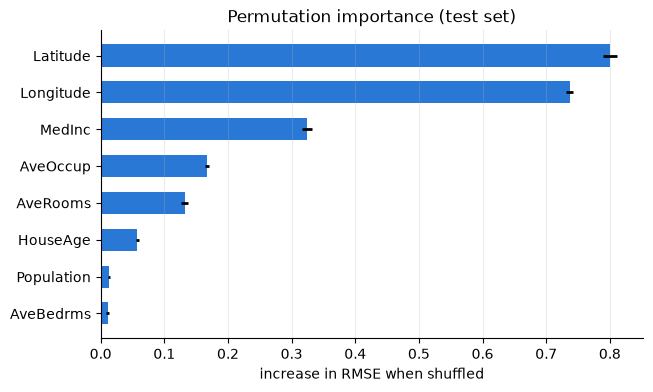

In [3]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=SEED, n_jobs=-1, scoring="neg_root_mean_squared_error")
pi_s = pd.Series(pi.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(pi_s.index, pi_s.values, xerr=pd.Series(pi.importances_std, index=X.columns)[pi_s.index], color=PALETTE[0], height=0.6)
ax.set_xlabel("increase in RMSE when shuffled"); ax.set_title("Permutation importance (test set)"); ax.grid(axis="y", visible=False)
plt.show()

## 2. Partial dependence + ICE
PDP = average prediction as one feature is swept over its range (others held at their observed values). ICE = the same curve for individual rows; if ICE lines have different shapes, the feature interacts with others.

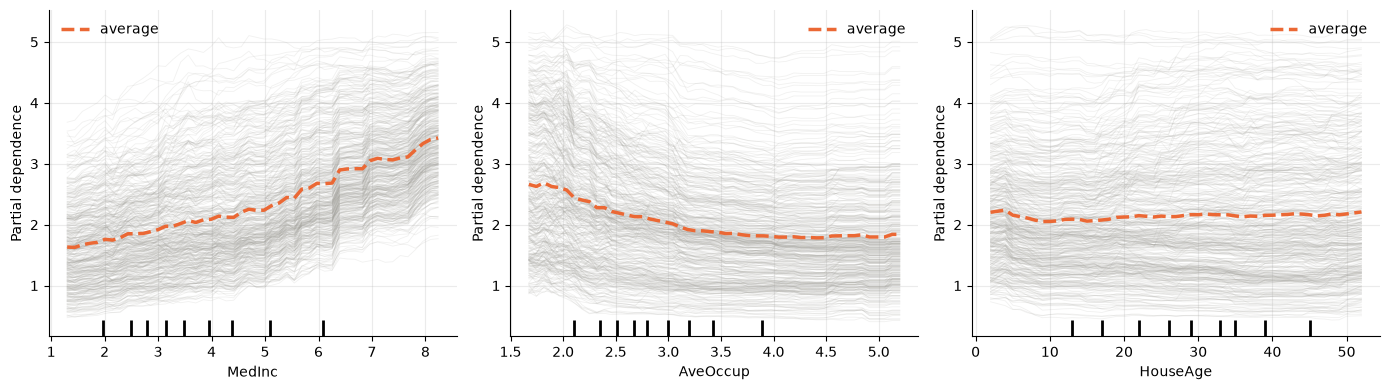

In [4]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
PartialDependenceDisplay.from_estimator(
    model, X_test.sample(400, random_state=SEED), ["MedInc", "AveOccup", "HouseAge"], kind="both",
    ax=axes, ice_lines_kw={"color": GREY, "alpha": 0.15, "linewidth": 0.6},
    pd_line_kw={"color": PALETTE[1], "linewidth": 2.5}, grid_resolution=50, percentiles=(0.02, 0.98),
)
plt.tight_layout()
plt.show()

## 3. SHAP values
SHAP splits each prediction into contributions: $\hat y_i = \text{base value} + \sum_j \phi_{ij}$.
For tree models `TreeExplainer` computes them exactly and fast.

- **Beeswarm:** each dot is one row; x = contribution, colour = the feature's value. Shows importance *and* direction.
- **Dependence:** contribution of one feature vs its value; vertical spread = interactions.
- **Waterfall:** explains a single prediction.

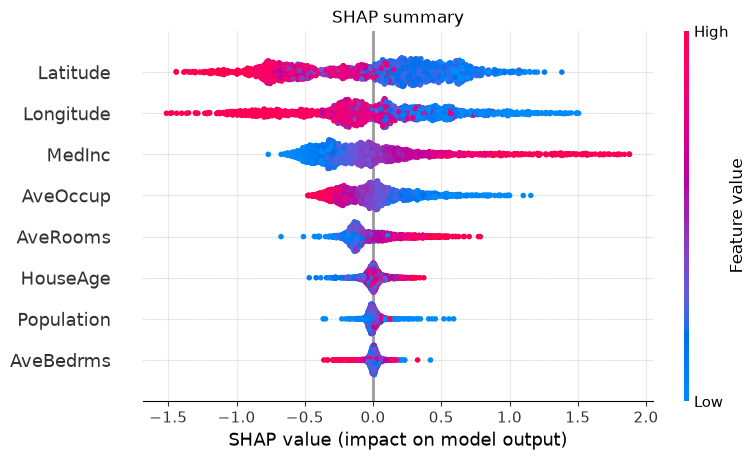

In [5]:
import shap

sample = X_test.sample(2000, random_state=SEED)
explainer = shap.TreeExplainer(model)
sv = explainer(sample)
shap.plots.beeswarm(sv, max_display=8, show=False)
plt.title("SHAP summary"); plt.tight_layout(); plt.show()

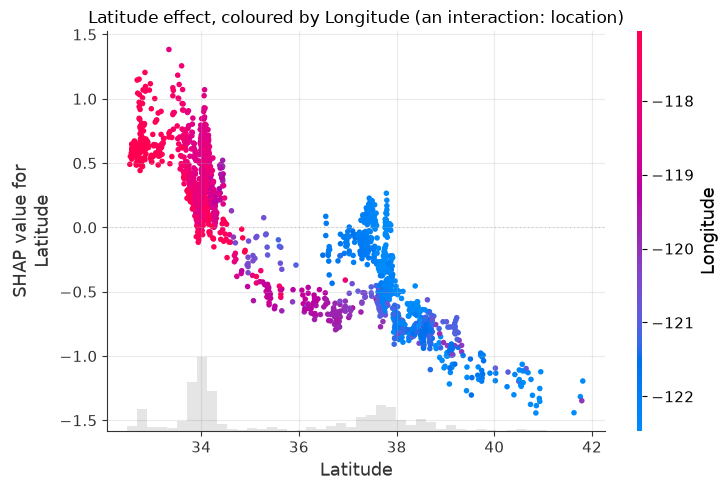

In [6]:
shap.plots.scatter(sv[:, "Latitude"], color=sv[:, "Longitude"], show=False)
plt.title("Latitude effect, coloured by Longitude (an interaction: location)"); plt.tight_layout(); plt.show()

explaining row with prediction 5.52 (base value 2.07)


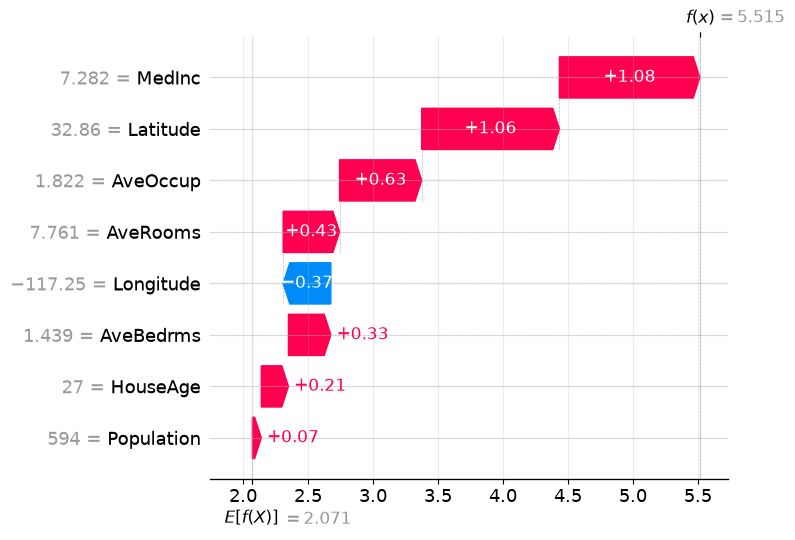

In [7]:
i = int(np.argmax(model.predict(sample)))
print(f"explaining row with prediction {model.predict(sample.iloc[[i]])[0]:.2f} (base value {sv.base_values[i]:.2f})")
shap.plots.waterfall(sv[i], max_display=8, show=False)
plt.tight_layout(); plt.show()

Sanity check: SHAP values add up exactly to the prediction.

In [8]:
recon = sv.base_values + sv.values.sum(1)
print("max |base + Σφ − prediction| =", float(np.abs(recon - model.predict(sample)).max()))

max |base + Σφ − prediction| = 3.863576125695545e-14


## Takeaways
- Use **permutation importance on held-out data** for "what matters", not built-in impurity/gain importance.
- **PDP/ICE** for the *shape* of an effect; diverging ICE lines reveal interactions.
- **SHAP** for direction, interactions and single-prediction explanations. LightGBM/XGBoost/CatBoost can also return SHAP natively (`pred_contrib=True`, `pred_contribs=True`, `type="ShapValues"`).
- Correlated features (Latitude/Longitude here) split credit, so interpret them as a group.
- Use interpretation to **debug**: a surprisingly important feature is often a leak.